In [634]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import spacy
from tqdm import tqdm
import re
import time
import pickle
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()
from nltk.tokenize import word_tokenize
# import tensorflow_hub as hub
# # import tensorflow as tf
#from nltk.corpus import stopwords
from keras.preprocessing.text import one_hot
from keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.layers import Conv1D,MaxPooling1D, LSTM,GlobalMaxPool1D, Bidirectional,Masking
from sklearn.model_selection import train_test_split
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import RandomizedSearchCV
import mysql.connector
import credentials_History
import twitter_settings  
import imp 
imp.reload(twitter_settings)
imp.reload(credentials_History)
from twitter_settings import *
from keras.utils import to_categorical


%matplotlib inline
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)


In [4]:
# import tensorflow as tf
# print(tf.__version__)

In [5]:
#elmo = hub.Module("https://tfhub.dev/google/elmo/2", trainable=True)

In [467]:
def connect_db():
    mydb = mysql.connector.connect(
        host="localhost",
        user="root",
        password="******",
        database="TwitterDB",
        auth_plugin='mysql_native_password',
        charset='utf8'  
    )
    
    return mydb

def close_db(mydb):
    mydb.close()

In [468]:
netflix_db_query = "SELECT text, compound_score FROM {} ".format(twitter_settings.TABLE_NAME)
print(netflix_db_query)

## Open db connection
mydb = connect_db()

train = pd.read_sql(netflix_db_query,con=mydb)

##close db connection
close_db(mydb)


SELECT text, compound_score FROM All_Tweets_Combined 


In [469]:
train.shape

(8855, 2)

## Lets divide the dataframe into rain and validation set

In [470]:
#randomly select 1500 tweets 
test_validation = train.ix[np.random.choice(train.index, 1500)]
print(test_validation.shape)
test_validation

(1500, 2)


,text,compound_score
4703,Dixon had to scan a new item every 11 seconds ...,0.1779
8490,Watching all 4 Scream movies on Netflix got me...,-0.0516
3851,Franeker New Tablet wall holder for your weath...,0.4588
7656,Cavill pleace leave it before it s too late Wi...,-0.0516
8090,Please watch Living Undocumented on Netflix,0.3182
7428,75 Itll e on Netflix today had a limited theat...,0.3818
2403,I was contemplating if I should sign up for Di...,0.5023
5067,My idea for a new Goosebumps Episode Slappy th...,0.4019
6199,Torrent kar raha hoon Don t have patience for ...,0.0000
5735,Netflix continues to churn out absolute aborti...,0.4497


## Lets remove these indexed rows from the original dataframe

In [194]:
print('train shape before droping test validation rows: {0}'.format(train.shape))
train.drop(test_validation.index,inplace=True)
train.reset_index(drop=True)
print('train shape after droping test validation rows: {0}'.format(train.shape))
train

train shape before droping test validation rows: (8855, 2)
train shape after droping test validation rows: (7468, 2)


,text,compound_score
2,will they address this in the disney remake,0.0000
4,Netflix really got fleeced into giving us a sh...,-0.2960
5,To move HBO to a mass strategy makes no sense ...,0.3818
8,Dat disney amp bet pressure,-0.2960
9,Im gonna tell my kids that Justin Bieber inven...,0.0000
10,ladies and gents my first first love a netflix...,0.7579
13,I just watched my first Netflix Heartstrings I...,0.8221
15,Klaus Netflix is beautifully animated and a he...,0.8020
16,Same as netflix,0.0000
17,If someone pauses their netflix or youtube vid...,0.7751


## Lets reset index of test validation dataframe as well

In [189]:
#reset index of validate dataframe
test_validation.reset_index(drop=True)
test_validation.shape

(1500, 2)

## Label meaning
- positive sentiment: compound score >= 0.05
- neutral sentiment: (compound score > -0.05) and (compound score < 0.05)
- negative sentiment: compound score <= -0.05

In [32]:
train.head()

,text,compound_score
1,I dont know but I lost it Good lord It feels w...,-0.7579
2,will they address this in the disney remake,0.0000
4,Netflix really got fleeced into giving us a sh...,-0.2960
5,To move HBO to a mass strategy makes no sense ...,0.3818
7,is the most underrated show on Netflix,0.0000


In [33]:
test_validation.head()

,text,compound_score
2681,BRUHH The short film float on Disney Woww,0.0000
6352,Some people watch a couple of netflix document...,-0.1280
2459,If you have Netflix and I suspect the majority...,-0.2960
5004,End of Watch is on Netflix everyone,0.0000
4126,so youre telling me netflix will cancel one of...,-0.7269


In [34]:
def clean_tweet(tweet): 
     
    ##Use sumple regex statemnents to clean tweet text by removing links and special characters
    
    tweet_text= ' '.join(re.sub("(RT @[\w_]+:)|(@[A-Za-z0-9]+)|([^0-9A-Za-z \t])|(\w+:\/\/\S+)", " ", tweet).split()) 
    tweet_text = re.sub(r'(.)\1{2,}',r'\1\1',tweet_text)
    tweet_text = tweet_text.lower()
    return tweet_text

def deEmojify_tweet(text):
    
    ##Strip all non-ASCII characters to remove emoji characters
    
    if text:
        return text.encode('ascii', 'ignore').decode('ascii')
    else:
        return None

In [35]:
train['text'] = train['text'].apply(clean_tweet)
train['text'] = train['text'].apply(deEmojify_tweet)
train.head()

,text,compound_score
1,i dont know but i lost it good lord it feels w...,-0.7579
2,will they address this in the disney remake,0.0000
4,netflix really got fleeced into giving us a sh...,-0.2960
5,to move hbo to a mass strategy makes no sense ...,0.3818
7,is the most underrated show on netflix,0.0000


In [36]:
test_validation['text'] = test_validation['text'].apply(clean_tweet)
test_validation['text'] = test_validation['text'].apply(deEmojify_tweet)
test_validation.head()

,text,compound_score
2681,bruhh the short film float on disney woww,0.0000
6352,some people watch a couple of netflix document...,-0.1280
2459,if you have netflix and i suspect the majority...,-0.2960
5004,end of watch is on netflix everyone,0.0000
4126,so youre telling me netflix will cancel one of...,-0.7269


## Lemmatize or Text Normalization using spacy

In [37]:
nlp = spacy.load('en',disable=['parser','ner'])

In [38]:
def lemmatize_tweet(tweet):
    output_word = [token.lemma_ for token in nlp(tweet) if token.lemma_ != '-PRON-']
    return ' '.join(output_word)

In [39]:
train['clean_tweet'] = train['text'].apply(lemmatize_tweet)
train.head()

,text,compound_score,clean_tweet
1,i dont know but i lost it good lord it feels w...,-0.7579,i do not know but i lose good lord feel wrong ...
2,will they address this in the disney remake,0.0000,will address this in the disney remake
4,netflix really got fleeced into giving us a sh...,-0.2960,netflix really get fleece into give a shitty j...
5,to move hbo to a mass strategy makes no sense ...,0.3818,to move hbo to a mass strategy make no sense t...
7,is the most underrated show on netflix,0.0000,be the most underrated show on netflix


In [40]:
test_validation['clean_tweet'] = test_validation['text'].apply(lemmatize_tweet)
test_validation.head()

,text,compound_score,clean_tweet
2681,bruhh the short film float on disney woww,0.0000,bruhh the short film float on disney woww
6352,some people watch a couple of netflix document...,-0.1280,some people watch a couple of netflix document...
2459,if you have netflix and i suspect the majority...,-0.2960,if have netflix and i suspect the majority of ...
5004,end of watch is on netflix everyone,0.0000,end of watch be on netflix everyone
4126,so youre telling me netflix will cancel one of...,-0.7269,so be tell netflix will cancel one of first sh...


## Test Train Split and then define corpus

In [41]:
X = train[['clean_tweet']]
y = train[['compound_score']]

In [42]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.3)

In [43]:
X_train.shape

(5224, 1)

In [44]:
X_test.shape

(2240, 1)

## Tokenize on train

In [45]:
##corpus - positive and negative tweets
corpus = list(X_train['clean_tweet'])
print(corpus)

['era8 in addition if get one could also get disney password', 'ppl be really out here flex money on snap then ask ppl for disney and netflix account sad', 'have listen to netflix amp deal yet', 'i buy netflix for two device more', 'lapak halo aku jual app premium spotify premium netflix premium viu premium iflix vip hooq vip order or', 'ooo so that s why a bunch of jtbc drama will be on netflix soon', 'wait what season 3 have not yet make to american netflix and i feel have be very patient and now go away', 'why do i keep get error try to log into the app be the disney app system down', 'rick perry claim trump be choose by god i hear from own mouth watch the family on netflix the evangelica', 'behind the scene of netflix s live action adaption of hxh', 'netflix u be a bitch rn', 'se matarem o ander eu cancelo a netflix', 'no but i mean i watch netflix here and there', 'danai netflix think this be a top pick for and i kind of want to watch to see why man look like th', 'the club on net

In [46]:
##sentiment - positive(0) and negative (1)
sentiments = list(y_train['compound_score'])
sentiments

[0.0,
 -0.4767,
 0.0,
 0.0,
 0.8429,
 0.0,
 0.0,
 -0.5204,
 0.3382,
 0.0,
 -0.5859,
 0.0,
 -0.1531,
 0.5118,
 0.3612,
 -0.4939,
 0.1593,
 0.0,
 -0.5707,
 0.128,
 0.0,
 -0.6597,
 0.0,
 0.807,
 0.0,
 0.2481,
 0.3802,
 -0.4767,
 0.0,
 0.5719,
 0.0,
 0.0,
 -0.3182,
 0.0,
 0.1779,
 0.0,
 0.3818,
 0.631,
 0.0,
 0.4404,
 -0.3164,
 0.1779,
 0.0,
 0.1531,
 0.3612,
 -0.1779,
 0.0,
 0.1531,
 -0.3818,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.4215,
 0.7783,
 0.0,
 -0.2732,
 -0.2263,
 0.0,
 -0.3595,
 -0.5574,
 0.25,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.2755,
 0.0,
 0.6597,
 -0.25,
 -0.296,
 0.0,
 0.4588,
 -0.3182,
 0.0,
 0.784,
 0.7501,
 0.6249,
 0.3818,
 0.4497,
 0.0,
 0.4588,
 0.0,
 -0.5413,
 0.7783,
 0.5562,
 0.1226,
 0.0,
 0.6249,
 0.7783,
 0.0,
 0.0,
 -0.4767,
 0.0,
 0.0,
 0.0,
 0.3612,
 0.0,
 0.4019,
 0.3612,
 0.4019,
 0.0,
 0.0,
 0.0,
 0.0,
 0.792,
 -0.5574,
 0.0,
 0.6249,
 0.0,
 0.0,
 0.4215,
 0.7103,
 0.0,
 0.6939,
 0.4939,
 0.0,
 0.1779,
 -0.4926,
 0.4404,
 0.4939,
 0.5267,
 0.4019,
 0.0,
 0.0,


In [24]:
# def join_tweets(tweet):
#     return ''.join(tweet)

In [25]:
# all_words=''
# for sentence in train['clean_tweet']:
#     all_words = all_words + join_tweets(tweets)
# print(all_words)

In [47]:
def get_all_words_list(var_corpus):
    var_all_words_list = []
    for sentence in var_corpus:
        tokens = word_tokenize(sentence)
        for word in tokens:
            if((len(word)>2)):
                var_all_words_list.append(word)
    print(var_all_words_list)
    return var_all_words_list

In [48]:
all_words_list = get_all_words_list(corpus)

['era8', 'addition', 'get', 'one', 'could', 'also', 'get', 'disney', 'password', 'ppl', 'really', 'out', 'here', 'flex', 'money', 'snap', 'then', 'ask', 'ppl', 'for', 'disney', 'and', 'netflix', 'account', 'sad', 'have', 'listen', 'netflix', 'amp', 'deal', 'yet', 'buy', 'netflix', 'for', 'two', 'device', 'more', 'lapak', 'halo', 'aku', 'jual', 'app', 'premium', 'spotify', 'premium', 'netflix', 'premium', 'viu', 'premium', 'iflix', 'vip', 'hooq', 'vip', 'order', 'ooo', 'that', 'why', 'bunch', 'jtbc', 'drama', 'will', 'netflix', 'soon', 'wait', 'what', 'season', 'have', 'not', 'yet', 'make', 'american', 'netflix', 'and', 'feel', 'have', 'very', 'patient', 'and', 'now', 'away', 'why', 'keep', 'get', 'error', 'try', 'log', 'into', 'the', 'app', 'the', 'disney', 'app', 'system', 'down', 'rick', 'perry', 'claim', 'trump', 'choose', 'god', 'hear', 'from', 'own', 'mouth', 'watch', 'the', 'family', 'netflix', 'the', 'evangelica', 'behind', 'the', 'scene', 'netflix', 'live', 'action', 'adaption'

In [49]:
print('words list length: {0}'.format(len(all_words_list)))
unique_words_set = set(all_words_list)
print('unique set of words length: {0}'.format(len(unique_words_set)))

words list length: 53111
unique set of words length: 7248


In [50]:
df1 = pd.DataFrame(data = all_words_list,columns=['words'])

In [51]:
df1['words'].value_counts()

netflix                            4355
the                                2294
and                                1472
watch                              1129
have                                840
disney                              745
for                                 662
not                                 648
that                                563
this                                561
with                                464
get                                 429
show                                408
just                                376
movie                               371
all                                 367
good                                332
can                                 330
but                                 318
what                                295
now                                 284
season                              282
amazon                              248
like                                247
out                                 247


In [52]:
vocab_length = len(unique_words_set) + 5

print('vocabl length: {0}'.format(vocab_length))

vocabl length: 7253


## Word embedding

In [53]:
corpus

['era8 in addition if get one could also get disney password',
 'ppl be really out here flex money on snap then ask ppl for disney and netflix account sad',
 'have listen to netflix amp deal yet',
 'i buy netflix for two device more',
 'lapak halo aku jual app premium spotify premium netflix premium viu premium iflix vip hooq vip order or',
 'ooo so that s why a bunch of jtbc drama will be on netflix soon',
 'wait what season 3 have not yet make to american netflix and i feel have be very patient and now go away',
 'why do i keep get error try to log into the app be the disney app system down',
 'rick perry claim trump be choose by god i hear from own mouth watch the family on netflix the evangelica',
 'behind the scene of netflix s live action adaption of hxh',
 'netflix u be a bitch rn',
 'se matarem o ander eu cancelo a netflix',
 'no but i mean i watch netflix here and there',
 'danai netflix think this be a top pick for and i kind of want to watch to see why man look like th',
 't

## Word embedding

In [54]:
embedded_sentences = [one_hot(sentence, vocab_length) for sentence in corpus]
print(embedded_sentences)

[[2419, 378, 2818, 2677, 1, 1626, 4946, 5099, 1, 4818, 3269], [1443, 3502, 1887, 6417, 1232, 1988, 5723, 4356, 4813, 2076, 5176, 1443, 6121, 4818, 2339, 3101, 823, 4367], [3385, 4941, 5543, 3101, 1346, 442, 2133], [4683, 6710, 3101, 6121, 3518, 16, 4936], [6057, 2822, 1992, 3902, 6657, 2647, 5430, 2647, 3101, 2647, 1537, 2647, 4181, 2619, 7170, 2619, 6454, 3113], [4827, 4739, 6556, 5532, 4066, 6701, 7089, 4995, 2608, 5321, 4736, 3502, 4356, 3101, 2340], [2727, 40, 6164, 5258, 3385, 2564, 2133, 5579, 5543, 4030, 3101, 2339, 4683, 763, 3385, 3502, 7028, 2300, 2339, 1969, 3382, 949], [4066, 5269, 4683, 4555, 1, 789, 4675, 5543, 6371, 2769, 3278, 6657, 3502, 3278, 4818, 6657, 78, 3396], [5663, 4874, 2914, 2688, 3502, 5486, 3349, 5558, 4683, 5175, 5727, 5267, 6969, 4315, 3278, 820, 4356, 3101, 3278, 2989], [888, 3278, 1228, 4995, 3101, 5532, 3752, 390, 7133, 4995, 4036], [3101, 2852, 3502, 6701, 1058, 2225], [6183, 6018, 1380, 4478, 5776, 6804, 6701, 3101], [1761, 2986, 4683, 5412, 4683, 43

In [55]:
max(embedded_sentences)

[7251,
 3278,
 3187,
 3128,
 378,
 6701,
 4280,
 5321,
 6701,
 709,
 29,
 2240,
 6798,
 4983,
 1841,
 1062,
 4315,
 4356,
 3101,
 858,
 4739,
 1697,
 3357]

#### To get max index of embedded word
- itertools.chain flattens the list of lists, the filter then selects all the numeric values of which the maximal value is then determined using the max function. Advantage here is that it also works for arbitrary lists of lists where the numeric value can be found anywhere in the list.

In [56]:
from itertools import chain
max_vocab_index = max(chain.from_iterable(embedded_sentences))
print(max_vocab_index)

7252


In [57]:
word_count = lambda sentence: len(word_tokenize(sentence))

In [58]:
longest_sentence = max(corpus, key=word_count)
length_long_sentence = len(word_tokenize(longest_sentence))

In [59]:
print(length_long_sentence)

29


## Word Embedding for X_test and train_validation as well

In [60]:
X_test_corpus = list(X_test['clean_tweet'])
X_test_embedded_sent = [one_hot(sentence, vocab_length) for sentence in X_test_corpus]
print(X_test_embedded_sent)

[[5303, 3278, 4818, 1316, 2339, 3502, 2564, 4818, 5427, 2174], [1278, 1312, 2278, 984, 6830, 763, 1139, 6878, 1816, 693, 2267, 3101, 1984, 2143, 2502, 4995, 6878], [1969, 6556, 6898, 3502, 6701, 9, 9, 5646, 4683, 1062, 3102, 6556, 4683, 103, 4983, 2218, 4356, 3101, 4683, 3385, 3502, 5170, 3147], [1433, 1956, 1332, 4678, 1347, 6079, 6556, 3502, 4315, 4315, 3101, 6764, 3349, 496, 3349, 3478, 3278, 987], [3101, 781, 3766, 5759], [4818, 2339, 3345], [4615, 2339, 593, 1650, 3004, 6701, 1171, 4216, 328, 4402, 3112, 805, 3642, 3101, 2472, 462, 4113, 3682, 136], [3101, 6898, 6839, 5397, 2263], [981, 3101, 2339, 6224, 5222, 4899, 3368, 6342, 6164], [2044, 4777, 7156, 5283, 3101, 698, 7109, 5543, 5728, 4791, 6872, 2339, 4936, 4387], [4683, 854, 3278, 1418, 2986, 3385, 2564, 3555, 2133, 5346, 4356, 3101, 2340], [1139, 6342, 2174, 4818, 3502, 3502, 30, 5543, 4315, 4227, 5296, 4683, 4503], [25, 3101, 1649, 3042, 4995, 4315, 5070, 3091], [2677, 4683, 6168, 1010, 6121, 4663, 5276, 4066, 5269, 4683, 3

In [61]:
test_validation_corpus = list(test_validation['clean_tweet'])
test_validation_embedded_sent = [one_hot(sentence, vocab_length) for sentence in test_validation_corpus]
print(test_validation_embedded_sent)

[[7049, 3278, 746, 6878, 7021, 4356, 4818, 3788], [3166, 6711, 4315, 6701, 5923, 4995, 3101, 3495, 2339, 2308, 2631, 2461, 4750, 4356, 1750, 3502, 3382, 4356, 378, 3278, 3289, 4282], [2677, 3385, 3101, 2339, 4683, 101, 3278, 2123, 4995, 5269, 443, 5123, 2546, 740, 6417, 3278, 1002, 6556, 5579, 4683, 3185, 4983], [3042, 4995, 4315, 3502, 4356, 3101, 2400], [4739, 3502, 4959, 3101, 4736, 5940, 1626, 4995, 6798, 1897, 6556, 2888, 1109, 6711, 888, 3296, 1853, 2339], [2045, 1346, 1, 4818, 1346, 1173, 4683, 5255, 5543, 7162, 3502], [3272, 1189, 5099, 1115, 5420, 4689, 6701, 6440, 4339, 3101, 3727, 1346, 7141, 4892, 515, 6476, 3278, 6373, 1272, 1703], [3502, 1887, 1010, 6121, 2973, 4036, 5543, 4315, 1361, 4818, 2339, 3101, 481, 481], [1062, 5067, 2247, 6701, 1139, 29, 5543, 4315, 4356, 3101, 1982, 4683, 3185, 299], [3101, 1887, 3502, 378, 5532, 6142, 5989, 4818, 3717, 6364, 5502], [7024, 5532, 2930, 6164, 3717, 62, 848, 1621, 5543, 3101, 2173, 7024, 4220], [3498, 6204, 6164, 3518, 1418, 6701,

## Padding

In [62]:
padded_sentences = pad_sequences(embedded_sentences, length_long_sentence, padding='post')
print(padded_sentences)

[[2419  378 2818 ...    0    0    0]
 [1443 3502 1887 ...    0    0    0]
 [3385 4941 5543 ...    0    0    0]
 ...
 [4675 5543 4315 ...    0    0    0]
 [3278  820 3101 ...    0    0    0]
 [4683 6079 3385 ...    0    0    0]]


## Padding for X_test and test_validation

In [63]:
X_test_padded_sent = pad_sequences(X_test_embedded_sent, length_long_sentence, padding='post')
print(padded_sentences)

[[2419  378 2818 ...    0    0    0]
 [1443 3502 1887 ...    0    0    0]
 [3385 4941 5543 ...    0    0    0]
 ...
 [4675 5543 4315 ...    0    0    0]
 [3278  820 3101 ...    0    0    0]
 [4683 6079 3385 ...    0    0    0]]


In [64]:
test_validation_padded_sent = pad_sequences(test_validation_embedded_sent, length_long_sentence, padding='post')
print(test_validation_padded_sent)

[[7049 3278  746 ...    0    0    0]
 [3166 6711 4315 ...    0    0    0]
 [2677 3385 3101 ...    0    0    0]
 ...
 [6428 3385 6701 ...    0    0    0]
 [  62  223 3734 ...    0    0    0]
 [4683  854 3278 ...    0    0    0]]


## Modelling

In [96]:
nlp_model = Sequential()

In [97]:
nlp_model.add(Embedding(vocab_length,20,input_length=length_long_sentence))


In [98]:
nlp_model.add(Flatten())
nlp_model.add(Dense(1,activation='tanh'))

In [99]:
nlp_model.compile(optimizer='adam',loss='mean_squared_error',metrics=['acc'])

In [100]:
print(nlp_model.summary())

Model: "sequential_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_3 (Embedding)      (None, 29, 20)            145060    
_________________________________________________________________
flatten_4 (Flatten)          (None, 580)               0         
_________________________________________________________________
dense_4 (Dense)              (None, 1)                 581       
Total params: 145,641
Trainable params: 145,641
Non-trainable params: 0
_________________________________________________________________
None


In [101]:
history=nlp_model.fit(padded_sentences,y_train,epochs=10,verbose=1,
                     validation_data=(X_test_padded_sent, y_test))

Train on 5224 samples, validate on 2240 samples
Epoch 1/10
5224/5224 [==============================] - 0s 70us/sample - loss: 0.1390 - acc: 0.4014 - val_loss: 0.1347 - val_acc: 0.4031
Epoch 2/10
5224/5224 [==============================] - 0s 44us/sample - loss: 0.1052 - acc: 0.4014 - val_loss: 0.1157 - val_acc: 0.4031
Epoch 3/10
5224/5224 [==============================] - 0s 44us/sample - loss: 0.0583 - acc: 0.4014 - val_loss: 0.0995 - val_acc: 0.4031
Epoch 4/10
5224/5224 [==============================] - 0s 46us/sample - loss: 0.0293 - acc: 0.4014 - val_loss: 0.0961 - val_acc: 0.4031
Epoch 5/10
5224/5224 [==============================] - 0s 41us/sample - loss: 0.0168 - acc: 0.4014 - val_loss: 0.0943 - val_acc: 0.4022
Epoch 6/10
5224/5224 [==============================] - 0s 44us/sample - loss: 0.0108 - acc: 0.4014 - val_loss: 0.0944 - val_acc: 0.4018
Epoch 7/10
5224/5224 [==============================] - 0s 46us/sample - loss: 0.0078 - acc: 0.4014 - val_loss: 0.0959 - val_acc: 

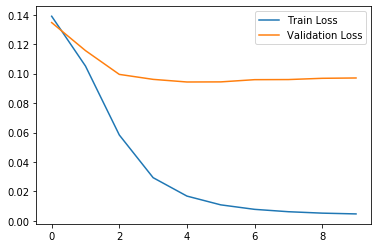

In [102]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [103]:
loss,accuracy = nlp_model.evaluate(X_test_padded_sent, y_test,verbose=1)

2240/2240 [==============================] - 0s 11us/sample - loss: 0.0971 - acc: 0.4004


In [104]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.09706204453749316
Val Accuracy: 40.04464149475098


## Dense Connected Layer - Convolutional1D Layer

In [90]:
padded_sentences.shape

(5224, 29)

In [91]:
X_test_padded_sent.shape

(2240, 29)

In [92]:
y_train.shape

(5224, 1)

In [93]:
vocab_length

7253

In [94]:
length_long_sentence

29

In [114]:
# model developing

n_filters, verbose, epochs, batch_size = 70, 1, 10, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
embedding_vec_length = 60

cnn_model = Sequential()

cnn_model.add(Embedding(vocab_length, embedding_vec_length, input_length=length_long_sentence))
cnn_model.add(Conv1D(filters=n_filters, kernel_size=2, padding='same',activation='relu', input_shape=(n_features,embedding_vec_length)))#input_shape=(n_rows,n_features)))
#cnn_model.add(Conv1D(filters=n_filters, kernel_size=2, padding='same',activation='relu', input_shape=(n_features,embedding_vec_length)))
#cnn_model.add(Conv1D(filters=n_filters, kernel_size=2, padding='same', activation='relu'))
#cnn_model.add(Dropout(0.5))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Flatten())
cnn_model.add(Dense(100, activation='relu'))
cnn_model.add(Dropout(0.2))
cnn_model.add(Dense(1, activation='linear'))
print(cnn_model.summary())


Model: "sequential_6"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_6 (Embedding)      (None, 29, 60)            435180    
_________________________________________________________________
conv1d_2 (Conv1D)            (None, 29, 70)            8470      
_________________________________________________________________
max_pooling1d_2 (MaxPooling1 (None, 14, 70)            0         
_________________________________________________________________
flatten_7 (Flatten)          (None, 980)               0         
_________________________________________________________________
dense_9 (Dense)              (None, 100)               98100     
_________________________________________________________________
dropout_2 (Dropout)          (None, 100)               0         
_________________________________________________________________
dense_10 (Dense)             (None, 1)                

In [115]:
cnn_model.compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy'])

In [116]:
# fit network
history = cnn_model.fit(padded_sentences, y_train, epochs=epochs, verbose=verbose, #batch_size=batch_size, 
                       validation_data=(X_test_padded_sent, y_test))

Train on 5224 samples, validate on 2240 samples
Epoch 1/10
5224/5224 [==============================] - 1s 252us/sample - loss: 0.1251 - acc: 0.4012 - val_loss: 0.0937 - val_acc: 0.4027
Epoch 2/10
5224/5224 [==============================] - 1s 192us/sample - loss: 0.0636 - acc: 0.4012 - val_loss: 0.0805 - val_acc: 0.4013
Epoch 3/10
5224/5224 [==============================] - 1s 195us/sample - loss: 0.0289 - acc: 0.4012 - val_loss: 0.0809 - val_acc: 0.4013
Epoch 4/10
5224/5224 [==============================] - 1s 193us/sample - loss: 0.0171 - acc: 0.4012 - val_loss: 0.0795 - val_acc: 0.4000
Epoch 5/10
5224/5224 [==============================] - 1s 193us/sample - loss: 0.0121 - acc: 0.4014 - val_loss: 0.0770 - val_acc: 0.4013
Epoch 6/10
5224/5224 [==============================] - 1s 192us/sample - loss: 0.0092 - acc: 0.4014 - val_loss: 0.0774 - val_acc: 0.3991
Epoch 7/10
5224/5224 [==============================] - 1s 199us/sample - loss: 0.0081 - acc: 0.4014 - val_loss: 0.0773 - va

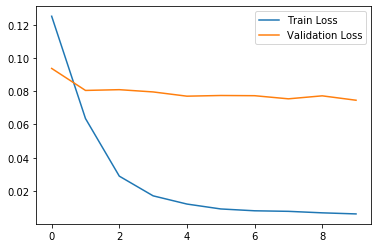

In [117]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [118]:
loss,accuracy = cnn_model.evaluate(X_test_padded_sent, y_test,verbose=1,batch_size=batch_size)

2240/2240 [==============================] - 0s 24us/sample - loss: 0.0746 - acc: 0.4004


In [119]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.07455593384802342
Val Accuracy: 40.04464149475098


## LSTM

In [120]:
# model developing

n_filters, verbose, epochs, batch_size = 100, 1, 10, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
print('vocab length: {0}'.format(vocab_length))
print('length of long sentence: {0}'.format(length_long_sentence))
lstm_model = Sequential()

lstm_model.add(Embedding(vocab_length, 50, input_length=length_long_sentence))
lstm_model.add(LSTM(128))
lstm_model.add(Dense(100, activation='relu'))
lstm_model.add(Dense(100))
#lstm_model.add(Dropout(0.2))
lstm_model.add(Dense(1, activation='linear'))
print(lstm_model.summary())


vocab length: 7253
length of long sentence: 29
Model: "sequential_7"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_7 (Embedding)      (None, 29, 50)            362650    
_________________________________________________________________
unified_lstm (UnifiedLSTM)   (None, 128)               91648     
_________________________________________________________________
dense_11 (Dense)             (None, 100)               12900     
_________________________________________________________________
dense_12 (Dense)             (None, 100)               10100     
_________________________________________________________________
dense_13 (Dense)             (None, 1)                 101       
Total params: 477,399
Trainable params: 477,399
Non-trainable params: 0
_________________________________________________________________
None


- You can now see that we have 610300 new parameters to train. This number comes from vocab_size times the embedding_dim. - Here 12206 * 50

In [121]:
lstm_model.compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy'])

In [122]:
# fit network
history = lstm_model.fit(padded_sentences, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test))

Train on 5224 samples, validate on 2240 samples
Epoch 1/10
5224/5224 [==============================] - 4s 851us/sample - loss: 0.1325 - acc: 0.4007 - val_loss: 0.1171 - val_acc: 0.4031
Epoch 2/10
5224/5224 [==============================] - 3s 645us/sample - loss: 0.0739 - acc: 0.3999 - val_loss: 0.1005 - val_acc: 0.4000
Epoch 3/10
5224/5224 [==============================] - 3s 645us/sample - loss: 0.0473 - acc: 0.4001 - val_loss: 0.0788 - val_acc: 0.4009
Epoch 4/10
5224/5224 [==============================] - 3s 655us/sample - loss: 0.0350 - acc: 0.4005 - val_loss: 0.0815 - val_acc: 0.3991
Epoch 5/10
5224/5224 [==============================] - 3s 655us/sample - loss: 0.0279 - acc: 0.4005 - val_loss: 0.0815 - val_acc: 0.3991
Epoch 6/10
5224/5224 [==============================] - 3s 665us/sample - loss: 0.0230 - acc: 0.4008 - val_loss: 0.0847 - val_acc: 0.3987
Epoch 7/10
5224/5224 [==============================] - 4s 692us/sample - loss: 0.0194 - acc: 0.4010 - val_loss: 0.0888 - va

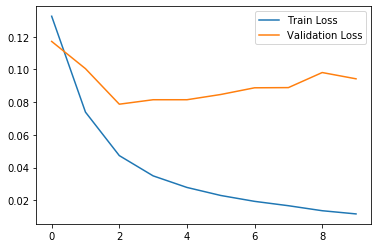

In [123]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [124]:
loss,accuracy = lstm_model.evaluate(X_test_padded_sent, y_test,verbose=1,batch_size=batch_size)

2240/2240 [==============================] - 1s 232us/sample - loss: 0.0943 - acc: 0.3969


In [125]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.0942675103034292
Val Accuracy: 39.68749940395355


## LSTM and Convolutional 1D

In [155]:
# model developing

n_filters, verbose, epochs, batch_size = 100, 1, 15, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
embedding_vec_length=60
print('X train cols: {0}'.format(n_features))
print('vocab length: {0}'.format(vocab_length))
print('length of long sentence: {0}'.format(length_long_sentence))
lstm_conv_model = Sequential()
lstm_conv_model.add(Embedding(vocab_length, embedding_vec_length, input_length=length_long_sentence))

lstm_conv_model.add(Conv1D(filters=n_filters, kernel_size=2,padding='same', activation='tanh', 
                           input_shape=(n_features,embedding_vec_length)))
# lstm_conv_model.add(Conv1D(filters=n_filters, kernel_size=3, activation='relu', input_shape=(n_rows,n_features)))
# lstm_conv_model.add(Conv1D(filters=n_filters, kernel_size=3, activation='relu'))
# #lstm_conv_model.add(Dropout(0.5))
lstm_conv_model.add(MaxPooling1D(pool_size=int(n_features/2)))
lstm_conv_model.add(LSTM(128))
lstm_conv_model.add(Dense(100, activation='tanh'))
lstm_conv_model.add(Dense(100))

#lstm_conv_model.add(Dropout(0.2))
lstm_conv_model.add(Dense(1, activation='linear'))
print(lstm_conv_model.summary())

X train cols: 29
vocab length: 7253
length of long sentence: 29
Model: "sequential_26"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_26 (Embedding)     (None, 29, 60)            435180    
_________________________________________________________________
conv1d_21 (Conv1D)           (None, 29, 100)           12100     
_________________________________________________________________
max_pooling1d_9 (MaxPooling1 (None, 2, 100)            0         
_________________________________________________________________
unified_lstm_19 (UnifiedLSTM (None, 128)               117248    
_________________________________________________________________
dense_56 (Dense)             (None, 100)               12900     
_________________________________________________________________
dense_57 (Dense)             (None, 100)               10100     
_______________________________________________________

In [158]:
lstm_conv_model.compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy'])

In [159]:
# fit network
history = lstm_conv_model.fit(padded_sentences, y_train, epochs=epochs, batch_size=batch_size, verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test))

Train on 5224 samples, validate on 2240 samples
Epoch 1/15
5224/5224 [==============================] - 6s 1ms/sample - loss: 11.9077 - acc: 0.3132 - val_loss: 0.1743 - val_acc: 0.3777
Epoch 2/15
5224/5224 [==============================] - 2s 325us/sample - loss: 0.0928 - acc: 0.3922 - val_loss: 0.1312 - val_acc: 0.3897
Epoch 3/15
5224/5224 [==============================] - 2s 325us/sample - loss: 0.0567 - acc: 0.3987 - val_loss: 0.1138 - val_acc: 0.3969
Epoch 4/15
5224/5224 [==============================] - 2s 326us/sample - loss: 0.0439 - acc: 0.3993 - val_loss: 0.1082 - val_acc: 0.3996
Epoch 5/15
5224/5224 [==============================] - 2s 325us/sample - loss: 0.0357 - acc: 0.4005 - val_loss: 0.1053 - val_acc: 0.3996
Epoch 6/15
5224/5224 [==============================] - 2s 325us/sample - loss: 0.0297 - acc: 0.4008 - val_loss: 0.1039 - val_acc: 0.3996
Epoch 7/15
5224/5224 [==============================] - 2s 322us/sample - loss: 0.0256 - acc: 0.4008 - val_loss: 0.1039 - val

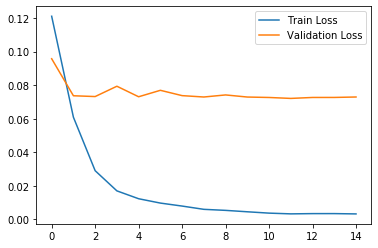

In [152]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [153]:
loss,accuracy = lstm_conv_model.evaluate(X_test_padded_sent, y_test,verbose=1,batch_size=batch_size)

2240/2240 [==============================] - 0s 87us/sample - loss: 0.0730 - acc: 0.3982


In [154]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.07295450054641281
Val Accuracy: 39.821428060531616


## Hyperparameter Optimization

In [160]:
def create_model(num_filters,kernel_size,vocab_size,embedding_dim,maxlen):
    model = Sequential()
    model.add(Embedding(vocab_size,embedding_dim,input_length=maxlen))
    model.add(Conv1D(num_filters,kernel_size,activation='tanh'))
    model.add(Bidirectional(LSTM(128, return_sequences=True, dropout=0.5)))
    model.add(GlobalMaxPool1D())
    model.add(Dense(10,activation='tanh'))
    model.add(Dense(1,activation='linear'))
    print(model.summary())
    model.compile(loss='mean_squared_error',optimizer='adam',metrics=['accuracy'])
    return model

In [161]:
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.callbacks import ModelCheckpoint
# Main settings
epochs = 5
embedding_dim=50
maxlen=length_long_sentence
batch_size=30
verbose=1

vocab_size = max_vocab_index + 5

#parameter grid for grid search
param_grid = dict(num_filters=[32,64,128],
                 kernel_size=[2,3,5],
                 vocab_size = [vocab_size],
                 embedding_dim = [embedding_dim],
                 maxlen = [maxlen])

hyperparam_model = KerasClassifier(build_fn=create_model,
                                  epochs=epochs,
                                  batch_size=batch_size,
                                  verbose=verbose)

grid = RandomizedSearchCV(estimator=hyperparam_model,
                         param_distributions=param_grid,
                         cv=5,
                         verbose=verbose,
                         n_iter=5)

callback_list = [
        EarlyStopping(
            monitor='val_loss',
            patience=10,
            verbose=1,
            mode='auto'
        )
#     ,
#         ModelCheckpoint(
#             monitor='val_acc',
#             save_best_only='True',
#             verbose=1,
#             mode='max'
#         )
    ]

## fit X_train and y_train in grid
grid_result = grid.fit(padded_sentences,y_train)#,callbacks=callback_list)

#Evaluate test set
test_accuracy = grid.score(X_test_padded_sent,y_test)


# Save and evaluate results
print('Results from Grid Search')
print('Best params: {0}'.format(grid_result.best_params_))
print('Best Accuracy: {0}'.format(round(grid_result.best_score_,2)))
print('Test Accuracy: {0}'.format(round(test_accuracy,2)))



Fitting 5 folds for each of 5 candidates, totalling 25 fits


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


Model: "sequential_27"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_27 (Embedding)     (None, 29, 50)            362850    
_________________________________________________________________
conv1d_22 (Conv1D)           (None, 28, 128)           12928     
_________________________________________________________________
bidirectional_12 (Bidirectio (None, 28, 256)           263168    
_________________________________________________________________
global_max_pooling1d_12 (Glo (None, 256)               0         
_________________________________________________________________
dense_59 (Dense)             (None, 10)                2570      
_________________________________________________________________
dense_60 (Dense)             (None, 1)                 11        
Total params: 641,527
Trainable params: 641,527
Non-trainable params: 0
_______________________________________________

Epoch 1/5
4180/4180 [==============================] - 11s 3ms/sample - loss: 108132.6104 - acc: 2.3923e-04
Epoch 2/5
4180/4180 [==============================] - 6s 1ms/sample - loss: 107035.8350 - acc: 2.3923e-04
Epoch 3/5
4180/4180 [==============================] - 6s 1ms/sample - loss: 106108.7033 - acc: 2.3923e-04
Epoch 4/5
4180/4180 [==============================] - 6s 1ms/sample - loss: 105195.0707 - acc: 2.3923e-04
Epoch 5/5
1044/1044 [==============================] - 3s 3ms/sample - loss: 104692.0767 - acc: 0.0000e+00
Model: "sequential_32"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_32 (Embedding)     (None, 29, 50)            362850    
_________________________________________________________________
conv1d_27 (Conv1D)           (None, 28, 32)            3232      
_________________________________________________________________
bidirectional_17 (Bidirectio (None, 28, 256) 

Epoch 1/5
4180/4180 [==============================] - 12s 3ms/sample - loss: 108247.3912 - acc: 2.3923e-04
Epoch 2/5
4180/4180 [==============================] - 6s 1ms/sample - loss: 107139.0242 - acc: 2.3923e-04
Epoch 3/5
4180/4180 [==============================] - 6s 2ms/sample - loss: 106210.1998 - acc: 2.3923e-04
Epoch 4/5
4180/4180 [==============================] - 6s 1ms/sample - loss: 105295.1420 - acc: 2.3923e-04
Epoch 5/5
1044/1044 [==============================] - 3s 3ms/sample - loss: 104788.8817 - acc: 0.0000e+00
Model: "sequential_37"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_37 (Embedding)     (None, 29, 50)            362850    
_________________________________________________________________
conv1d_32 (Conv1D)           (None, 25, 32)            8032      
_________________________________________________________________
bidirectional_22 (Bidirectio (None, 25, 256) 

KeyboardInterrupt: 

## Fit the model using best params

In [169]:
vocab_size = grid_result.best_params_['vocab_size']
num_filters = grid_result.best_params_['num_filters']
kernel_size = grid_result.best_params_['kernel_size']
embedding_dim = grid_result.best_params_['embedding_dim']
maxlen = grid_result.best_params_['maxlen']

# Build fine model with best param
fine_model = create_model(num_filters,kernel_size,vocab_size,embedding_dim,maxlen)



Model: "sequential_226"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_226 (Embedding)    (None, 52, 50)            610500    
_________________________________________________________________
conv1d_223 (Conv1D)          (None, 51, 64)            6464      
_________________________________________________________________
bidirectional_56 (Bidirectio (None, 51, 256)           197632    
_________________________________________________________________
global_max_pooling1d_178 (Gl (None, 256)               0         
_________________________________________________________________
dense_434 (Dense)            (None, 10)                2570      
_________________________________________________________________
dense_435 (Dense)            (None, 1)                 11        
Total params: 817,177
Trainable params: 817,177
Non-trainable params: 0
______________________________________________

In [170]:
# fit network
history = fine_model.fit(padded_sentences, y_train, epochs=epochs,
                                  batch_size=batch_size,
                                  verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test))

Train on 5544 samples, validate on 2376 samples
Epoch 1/5
5544/5544 [==============================] - 61s 11ms/sample - loss: 0.4069 - acc: 0.8158 - val_loss: 0.2839 - val_acc: 0.8750
Epoch 2/5
5544/5544 [==============================] - 40s 7ms/sample - loss: 0.2156 - acc: 0.9145 - val_loss: 0.2990 - val_acc: 0.8699
Epoch 3/5
5544/5544 [==============================] - 40s 7ms/sample - loss: 0.1553 - acc: 0.9437 - val_loss: 0.3277 - val_acc: 0.8611
Epoch 4/5
5544/5544 [==============================] - 40s 7ms/sample - loss: 0.1100 - acc: 0.9627 - val_loss: 0.3885 - val_acc: 0.8607
Epoch 5/5
5544/5544 [==============================] - 41s 7ms/sample - loss: 0.0800 - acc: 0.9742 - val_loss: 0.4682 - val_acc: 0.8577


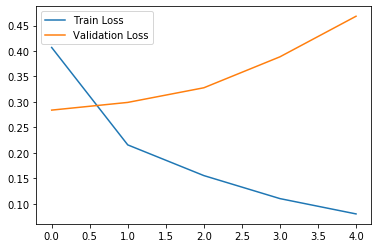

In [171]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [172]:
loss,accuracy = lstm_conv_model.evaluate(X_test_padded_sent, y_test,verbose=1,batch_size=batch_size)

2376/2376 [==============================] - 1s 393us/sample - loss: 0.4463 - acc: 0.8485


In [173]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.44634811397679525
Val Accuracy: 84.84848737716675


## Extra

In [ ]:
# # Instantiate a CNN.
# cnn_model_1 = Sequential()

# # Add a convolutional layer.
# cnn_model_1.add(Conv1D(filters = 16,         # number of filters
#                      kernel_size = 3,        # height/width of filter
#                      activation='relu',      # activation function 
#                      input_length=length_long_sentence)) # shape of input (image)

# # Add a pooling layer.
# cnn_model_1.add(MaxPooling1D(pool_size=(2,2))) # dimensions of region of pooling

# # Add another convolutional layer.
# cnn_model_1.add(Conv1D(64,
#                        kernel_size = 3,
#                        activation='relu'))

# # Add another pooling layer.
# cnn_model_1.add(MaxPooling1D(pool_size=(2,2)))

# # We have to remember to flatten to go from the "box" to the vertical line of nodes!
# cnn_model_1.add(Flatten())

# # Add a densely-connected layer with 64 neurons.
# cnn_model_1.add(Dense(64, activation='relu'))

# # Let's try to avoid overfitting!
# cnn_model_1.add(Dropout(0.5))

# # Add a densely-connected layer with 32 neurons.
# cnn_model_1.add(Dense(32, activation='relu'))

# # Let's try to avoid overfitting!
# cnn_model_1.add(Dropout(0.5))

# # Add a final layer with 10 neurons.
# cnn_model_1.add(Dense(10, activation='sigmoid'))

# # Compile model
# cnn_model_1.compile(loss='binary_crossentropy',
#                     optimizer='adam',
#                     metrics=['accuracy'])

# # Fit model on training data
# history = cnn_model_2.fit(padded_sentences,sentiments,
#                           batch_size=128,
#                           validation_data=(X_test_padded_sent, y_test),
#                           epochs=20,
#                           verbose=1)


## get the overall polarity instead of compound score and try to build mdoel

In [656]:
netflix_pol_db_query = "SELECT text, polarity  FROM {} ".format(twitter_settings.TABLE_NAME)
print(netflix_pol_db_query)

## Open db connection
mydb = connect_db()

train_pol = pd.read_sql(netflix_pol_db_query,con=mydb)

##close db connection
close_db(mydb)
train_pol.shape

SELECT text, polarity  FROM All_Tweets_Combined 


(8855, 2)

In [657]:
train_pol

,text,polarity
0,Return to Pandora Avatar is streaming now only...,0
1,I dont know but I lost it Good lord It feels w...,-1
2,will they address this in the disney remake,0
3,I wanna get disney but I dont have time to wat...,-1
4,Netflix really got fleeced into giving us a sh...,-1
5,To move HBO to a mass strategy makes no sense ...,1
6,So Netflix has this movie called Cargo which i...,1
7,is the most underrated show on Netflix,0
8,Dat disney amp bet pressure,-1
9,Im gonna tell my kids that Justin Bieber inven...,0


In [658]:
train_pol['polarity'] = train_pol['polarity'].map({0:0,1:1,-1:2})
train_pol

,text,polarity
0,Return to Pandora Avatar is streaming now only...,0
1,I dont know but I lost it Good lord It feels w...,2
2,will they address this in the disney remake,0
3,I wanna get disney but I dont have time to wat...,2
4,Netflix really got fleeced into giving us a sh...,2
5,To move HBO to a mass strategy makes no sense ...,1
6,So Netflix has this movie called Cargo which i...,1
7,is the most underrated show on Netflix,0
8,Dat disney amp bet pressure,2
9,Im gonna tell my kids that Justin Bieber inven...,0


## Lets divide the dataframe into rain and validation set

In [659]:
#randomly select 1500 tweets for validation set
test_pol_validation = train_pol.ix[np.random.choice(train_pol.index, 1500)]
test_pol_validation.shape

(1500, 2)

In [660]:
test_pol_validation

,text,polarity
3569,Actually Netflix posted about it first then moira,0
4898,Nov 26 update I see a Continue Watching featur...,1
5568,4 Netflix,0
3373,Do you recommend any Netflix series,1
8616,What to watch on netflix,0
3772,Yeah we can tell you watch Netflix all week wh...,1
5505,Learns Elot Why should you pay for Netflix,2
7686,Xo is it on netflix,0
8124,Well this quite a surprise but Netflix just an...,1
8449,Netflix and chill uwu,0


In [661]:
test_pol_validation.index.sort_values()

Int64Index([   3,   11,   13,   17,   36,   38,   39,   40,   44,   48,
            ...
            8827, 8832, 8832, 8835, 8837, 8842, 8844, 8849, 8850, 8851],
           dtype='int64', length=1500)

In [662]:
train_pol.index.unique

<bound method Index.unique of RangeIndex(start=0, stop=8855, step=1)>

## Lets remove these indexed rows from the original dataframe

In [663]:
print('train shape before droping test validation rows: {0}'.format(train_pol.shape))
train_pol.drop(index=test_pol_validation.index,inplace=True)
train_pol.reset_index(inplace=True)
train_pol.drop(columns='index',inplace=True)
print('train shape after droping test validation rows: {0}'.format(train_pol.shape))
train_pol.head(5)

train shape before droping test validation rows: (8855, 2)
train shape after droping test validation rows: (7486, 2)


,text,polarity
0,Return to Pandora Avatar is streaming now only...,0
1,I dont know but I lost it Good lord It feels w...,2
2,will they address this in the disney remake,0
3,Netflix really got fleeced into giving us a sh...,2
4,To move HBO to a mass strategy makes no sense ...,1


## Reset index of test_validation

In [664]:
#reset index of validate dataframe
test_pol_validation=test_pol_validation.reset_index(drop=True)
test_pol_validation.shape

(1500, 2)

## Label meaning
- positive sentiment: compound score >= 0.05
- neutral sentiment: (compound score > -0.05) and (compound score < 0.05)
- negative sentiment: compound score <= -0.05

In [665]:
train_pol.head()

,text,polarity
0,Return to Pandora Avatar is streaming now only...,0
1,I dont know but I lost it Good lord It feels w...,2
2,will they address this in the disney remake,0
3,Netflix really got fleeced into giving us a sh...,2
4,To move HBO to a mass strategy makes no sense ...,1


In [666]:
test_pol_validation.head()

,text,polarity
0,Actually Netflix posted about it first then moira,0
1,Nov 26 update I see a Continue Watching featur...,1
2,4 Netflix,0
3,Do you recommend any Netflix series,1
4,What to watch on netflix,0


In [667]:
train_pol['text'] = train_pol['text'].apply(clean_tweet)
#train_pol['text'] = train_pol['text'].apply(deEmojify_tweet)
train_pol.head()

,text,polarity
0,return to pandora avatar is streaming now only...,0
1,i dont know but i lost it good lord it feels w...,2
2,will they address this in the disney remake,0
3,netflix really got fleeced into giving us a sh...,2
4,to move hbo to a mass strategy makes no sense ...,1


In [668]:
test_pol_validation['text'] = test_pol_validation['text'].apply(clean_tweet)
#test_pol_validation['text'] = test_pol_validation['text'].apply(deEmojify_tweet)
test_pol_validation.head()

,text,polarity
0,actually netflix posted about it first then moira,0
1,nov 26 update i see a continue watching featur...,1
2,4 netflix,0
3,do you recommend any netflix series,1
4,what to watch on netflix,0


## Lemmatize or Text Normalization using spacy

In [669]:
nlp = spacy.load('en',disable=['parser','ner'])

In [670]:
def lemmatize_tweet(tweet):
    output_word = [token.lemma_ for token in nlp(tweet) if token.lemma_ != '-PRON-']
    return ' '.join(output_word)

In [671]:
train_pol['clean_tweet'] = train_pol['text'].apply(lemmatize_tweet)
train_pol.head()

,text,polarity,clean_tweet
0,return to pandora avatar is streaming now only...,0,return to pandora avatar be stream now only on...
1,i dont know but i lost it good lord it feels w...,2,i do not know but i lose good lord feel wrong ...
2,will they address this in the disney remake,0,will address this in the disney remake
3,netflix really got fleeced into giving us a sh...,2,netflix really get fleece into give a shitty j...
4,to move hbo to a mass strategy makes no sense ...,1,to move hbo to a mass strategy make no sense t...


In [672]:
test_pol_validation['clean_tweet'] = test_pol_validation['text'].apply(lemmatize_tweet)
test_pol_validation.head()

,text,polarity,clean_tweet
0,actually netflix posted about it first then moira,0,actually netflix post about first then moira
1,nov 26 update i see a continue watching featur...,1,nov 26 update i see a continue watch feature o...
2,4 netflix,0,4 netflix
3,do you recommend any netflix series,1,do recommend any netflix series
4,what to watch on netflix,0,what to watch on netflix


## Test Train Split and then define corpus

In [707]:
X = train_pol[['clean_tweet']]
y = train_pol[['polarity']]

In [708]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.3)

In [709]:
X_train.shape

(5240, 1)

In [710]:
X_test.shape

(2246, 1)

## Tokenize on train

In [711]:
##corpus - positive and negative tweets
corpus = list(X_train['clean_tweet'])
print(corpus)

['that s actually awesome be go to ask if on netflix', 'go for all on disney make a tweet thread bout too', 'yo season 4 do not even have to be on netflix have vpn please just make happen saveannewithane renewannewithane h', 'put love rosie back on netflix and guess who be cry tonight', 'just watch bikram on netflix and be so disturb please avoid this man and do not go to future teaching', 'should be 100 focus on the functionality and connectivity of disney rather than the ad right now', 'home alone on disneyplus before bed', 'jamesthebrain bloodlines on netflix kyle chandler will always be coach taylor to so this be basically coach', 'oh my god when netflix come out w icarly game over', 'a cloud gaming platform google launch netflix of game on november 19 check the whole new era of game all feature', 'that suck bro try to rest up doctor s order disney and chill', 'fullerhouse netflix netflix drops fuller house season 5 trailer without lori loughlin', 'niccole really what do think of i

In [713]:
##sentiment - positive(0) and negative (1)
sentiments = list(y_train['polarity'])
sentiments

[1,
 0,
 1,
 1,
 2,
 1,
 2,
 0,
 1,
 1,
 2,
 0,
 1,
 0,
 0,
 1,
 0,
 2,
 1,
 1,
 2,
 2,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 2,
 1,
 0,
 0,
 1,
 0,
 0,
 1,
 2,
 2,
 0,
 1,
 0,
 1,
 2,
 0,
 1,
 1,
 2,
 2,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 2,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 2,
 2,
 0,
 1,
 0,
 2,
 0,
 1,
 0,
 2,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 2,
 0,
 0,
 1,
 2,
 0,
 0,
 1,
 0,
 2,
 0,
 2,
 1,
 2,
 1,
 1,
 1,
 0,
 1,
 2,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 2,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 2,
 2,
 0,
 2,
 1,
 1,
 2,
 2,
 1,
 1,
 1,
 2,
 0,
 0,
 2,
 1,
 2,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 2,
 2,
 0,
 0,
 0,
 1,
 2,
 1,
 0,
 2,
 2,
 1,
 0,
 2,
 1,
 0,
 2,
 1,
 1,
 1,
 0,
 2,
 1,
 1,
 1,
 2,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 2,
 2,
 0,
 0,
 1,
 1,
 2,
 2,
 0,
 0,
 1,
 0,
 2,
 0,
 0,
 0,
 1,
 0,
 0,
 2,
 0,
 0,
 2,
 0,
 0,
 1,
 2,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 2,
 2,
 0,
 2,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 2,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 2,
 0,
 0,
 2,


In [24]:
# def join_tweets(tweet):
#     return ''.join(tweet)

In [25]:
# all_words=''
# for sentence in train['clean_tweet']:
#     all_words = all_words + join_tweets(tweets)
# print(all_words)

In [714]:
def get_all_words_list(var_corpus):
    var_all_words_list = []
    for sentence in var_corpus:
        tokens = word_tokenize(sentence)
        for word in tokens:
            if((len(word)>2)):
                var_all_words_list.append(word)
    print(var_all_words_list)
    return var_all_words_list

In [715]:
all_words_list = get_all_words_list(corpus)

['that', 'actually', 'awesome', 'ask', 'netflix', 'for', 'all', 'disney', 'make', 'tweet', 'thread', 'bout', 'too', 'season', 'not', 'even', 'have', 'netflix', 'have', 'vpn', 'please', 'just', 'make', 'happen', 'saveannewithane', 'renewannewithane', 'put', 'love', 'rosie', 'back', 'netflix', 'and', 'guess', 'who', 'cry', 'tonight', 'just', 'watch', 'bikram', 'netflix', 'and', 'disturb', 'please', 'avoid', 'this', 'man', 'and', 'not', 'future', 'teaching', 'should', '100', 'focus', 'the', 'functionality', 'and', 'connectivity', 'disney', 'rather', 'than', 'the', 'right', 'now', 'home', 'alone', 'disneyplus', 'before', 'bed', 'jamesthebrain', 'bloodlines', 'netflix', 'kyle', 'chandler', 'will', 'always', 'coach', 'taylor', 'this', 'basically', 'coach', 'god', 'when', 'netflix', 'come', 'out', 'icarly', 'game', 'over', 'cloud', 'gaming', 'platform', 'google', 'launch', 'netflix', 'game', 'november', 'check', 'the', 'whole', 'new', 'era', 'game', 'all', 'feature', 'that', 'suck', 'bro', 't

In [716]:
print('words list length: {0}'.format(len(all_words_list)))
unique_words_set = set(all_words_list)
print('unique set of words length: {0}'.format(len(unique_words_set)))

words list length: 52842
unique set of words length: 7235


In [717]:
vocab_length = len(unique_words_set) + 5

print('vocabl length: {0}'.format(vocab_length))

vocabl length: 7240


## Word embedding

In [718]:
corpus

['that s actually awesome be go to ask if on netflix',
 'go for all on disney make a tweet thread bout too',
 'yo season 4 do not even have to be on netflix have vpn please just make happen saveannewithane renewannewithane h',
 'put love rosie back on netflix and guess who be cry tonight',
 'just watch bikram on netflix and be so disturb please avoid this man and do not go to future teaching',
 'should be 100 focus on the functionality and connectivity of disney rather than the ad right now',
 'home alone on disneyplus before bed',
 'jamesthebrain bloodlines on netflix kyle chandler will always be coach taylor to so this be basically coach',
 'oh my god when netflix come out w icarly game over',
 'a cloud gaming platform google launch netflix of game on november 19 check the whole new era of game all feature',
 'that suck bro try to rest up doctor s order disney and chill',
 'fullerhouse netflix netflix drops fuller house season 5 trailer without lori loughlin',
 'niccole really what d

## Word embedding

In [719]:
embedded_sentences = [one_hot(sentence, vocab_length) for sentence in corpus]
print(embedded_sentences)

[[6101, 2279, 335, 6017, 3290, 5158, 6775, 6817, 3365, 4002, 1243], [5158, 4753, 5989, 4002, 1988, 2981, 3734, 1819, 2894, 1045, 3650], [3206, 7207, 251, 376, 1735, 4143, 5160, 6775, 3290, 4002, 1243, 5160, 6412, 442, 3562, 2981, 854, 4206, 4652, 4648], [5670, 4651, 6872, 3047, 4002, 1243, 2576, 2127, 1437, 3290, 4860, 2109], [3562, 3775, 1688, 4002, 1243, 2576, 3290, 190, 1800, 442, 1694, 1518, 619, 2576, 376, 1735, 5158, 6775, 6572, 1861], [5175, 3290, 4072, 4349, 4002, 1363, 348, 2576, 5346, 1760, 1988, 6649, 3385, 1363, 2910, 31, 5890], [4769, 4530, 4002, 87, 4166, 216], [6078, 6145, 4002, 1243, 1819, 6913, 3599, 1983, 3290, 2331, 6691, 6775, 190, 1518, 3290, 3865, 2331], [3207, 739, 3392, 6635, 1243, 6983, 1410, 1047, 6033, 4018, 7230], [3734, 3790, 756, 1924, 2747, 1986, 1243, 1760, 4018, 4002, 5157, 5209, 698, 1363, 4968, 1424, 296, 1760, 4018, 5989, 4764], [6101, 5427, 2358, 7069, 6775, 6049, 2159, 4097, 2279, 1222, 1988, 2576, 6909], [4583, 1243, 1243, 4511, 1566, 2867, 7207, 

In [720]:
max(embedded_sentences)

[7229,
 4753,
 5884,
 2001,
 2576,
 1424,
 906,
 4002,
 1243,
 4171,
 4058,
 6181,
 4783,
 4283,
 3981,
 2576,
 429,
 2762,
 6639]

#### To get max index of embedded word
- itertools.chain flattens the list of lists, the filter then selects all the numeric values of which the maximal value is then determined using the max function. Advantage here is that it also works for arbitrary lists of lists where the numeric value can be found anywhere in the list.

In [721]:
from itertools import chain
max_vocab_index = max(chain.from_iterable(embedded_sentences))
print(max_vocab_index)

7239


In [722]:
word_count = lambda sentence: len(word_tokenize(sentence))

In [723]:
longest_sentence = max(corpus, key=word_count)
length_long_sentence = len(word_tokenize(longest_sentence))

In [724]:
print(length_long_sentence)

29


## Word Embedding for X_test and train_validation as well

In [725]:
X_test_corpus = list(X_test['clean_tweet'])
X_test_embedded_sent = [one_hot(sentence, vocab_length) for sentence in X_test_corpus]
print(X_test_embedded_sent)

[[5437, 3599, 3290, 1363, 1929, 906, 6775, 6983, 1410, 1760, 1243], [4668, 1760, 3775, 3290, 4002, 1243, 5158, 6775, 5158, 4860, 3384], [7074, 3562, 1920, 2159, 4753, 3734, 102, 1760, 6283, 2073, 4002, 4765, 2463, 2576, 3736, 1243, 5843, 1061, 1760, 6101], [188, 908, 3392, 3734, 1143, 1243, 534, 3509, 190, 1324, 2576, 3290, 6373, 1760, 3032], [6678, 6101, 7207, 6126, 1760, 2195, 3290, 1735, 4002, 6462, 1243, 483], [31, 1243, 3290, 371, 2456, 97, 7207, 178, 908], [698, 1410, 6635, 4002, 1243], [1988, 2329, 6775, 3111, 1111, 1760, 4735, 2576, 5886, 3392, 1363, 2867], [6096, 7074, 3452, 832, 3290, 1526, 3623, 6373, 1760, 1363, 5100, 1705, 2509, 6313, 4002, 1243, 441, 6775, 1363, 6895, 1760, 6805], [3305, 3290, 190, 4327, 4002, 1243, 2162, 6101, 1243, 3290, 6679, 6775, 4824, 4751, 1157, 4002, 6775, 376, 2162, 1457, 2169, 7074, 6116], [1243, 5142], [5175, 3290, 5437, 2140, 1988, 3205, 1324], [2743, 4137, 1243, 4753, 5418, 6891, 6775, 105, 3734, 2187, 3677], [7074, 2743, 1735, 3775, 4751, 19

In [726]:
test_pol_validation_corpus = list(test_pol_validation['clean_tweet'])
    test_validation_embedded_sent = [one_hot(sentence, vocab_length) for sentence in test_validation_corpus]
print(test_validation_embedded_sent)

[[4807, 1363, 7068, 5295, 2510, 4002, 1988, 6900], [792, 6040, 3775, 3734, 4641, 1760, 1243, 4015, 2576, 170, 345, 4735, 1989, 4002, 3847, 3290, 5158, 4002, 3392, 1363, 4366, 2358], [3365, 5160, 1243, 2576, 7074, 4088, 1363, 5546, 1760, 376, 4962, 5134, 2938, 698, 1410, 1363, 3680, 6101, 2981, 7074, 796, 4651], [4668, 1760, 3775, 3290, 4002, 1243, 833], [190, 3290, 2408, 1243, 3599, 6910, 6373, 1760, 4232, 906, 6101, 7214, 4789, 6040, 31, 5112, 2715, 2576], [2887, 1871, 5361, 1988, 1871, 5989, 7074, 5695, 6775, 6412, 3290], [5537, 3176, 4543, 4026, 4652, 3385, 3734, 2834, 5687, 1243, 1425, 1871, 6146, 4482, 6323, 4783, 1363, 5366, 4166, 467], [3290, 2410, 887, 4753, 4968, 2867, 6775, 3775, 2278, 1988, 2576, 1243, 4368, 4368], [2743, 2573, 5801, 3734, 1929, 1157, 6775, 3775, 4002, 1243, 4212, 7074, 796, 4893], [1243, 2410, 3290, 3392, 2279, 514, 6523, 1988, 6679, 5223, 2665], [4160, 2279, 6959, 7207, 6679, 1518, 4685, 1688, 6775, 1243, 5889, 4160, 137], [6295, 2957, 7207, 2968, 2716, 37

## Padding

In [727]:
padded_sentences = pad_sequences(embedded_sentences, length_long_sentence, padding='post')
print(padded_sentences)

[[6101 2279  335 ...    0    0    0]
 [5158 4753 5989 ...    0    0    0]
 [3206 7207  251 ...    0    0    0]
 ...
 [1575  376 5214 ...    0    0    0]
 [2169  458 3048 ...    0    0    0]
 [ 698 1410 7177 ...    0    0    0]]


## Padding for X_test and test_validation

In [728]:
X_test_padded_sent = pad_sequences(X_test_embedded_sent, length_long_sentence, padding='post')
print(padded_sentences)

[[6101 2279  335 ...    0    0    0]
 [5158 4753 5989 ...    0    0    0]
 [3206 7207  251 ...    0    0    0]
 ...
 [1575  376 5214 ...    0    0    0]
 [2169  458 3048 ...    0    0    0]
 [ 698 1410 7177 ...    0    0    0]]


In [729]:
test_validation_padded_sent = pad_sequences(test_validation_embedded_sent, length_long_sentence, padding='post')
print(test_validation_padded_sent)

[[4807 1363 7068 ...    0    0    0]
 [ 792 6040 3775 ...    0    0    0]
 [3365 5160 1243 ...    0    0    0]
 ...
 [3812 5160 3734 ...    0    0    0]
 [1518 2980 3531 ...    0    0    0]
 [7074 5940 1363 ...    0    0    0]]


## Modelling

In [509]:
nlp_model = Sequential()

In [417]:
nlp_model.add(Embedding(vocab_length,20,input_length=length_long_sentence))


In [418]:
nlp_model.add(Flatten())
nlp_model.add(Dense(1,activation='tanh'))

In [419]:
nlp_model.compile(optimizer='adam',loss='mean_squared_error',metrics=['acc'])

In [420]:
print(nlp_model.summary())

Model: "sequential_84"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_82 (Embedding)     (None, 29, 20)            143800    
_________________________________________________________________
flatten_14 (Flatten)         (None, 580)               0         
_________________________________________________________________
dense_174 (Dense)            (None, 1)                 581       
Total params: 144,381
Trainable params: 144,381
Non-trainable params: 0
_________________________________________________________________
None


In [421]:
history=nlp_model.fit(padded_sentences,y_train,epochs=20,verbose=1,
                     validation_data=(X_test_padded_sent, y_test))

Train on 5229 samples, validate on 2242 samples
Epoch 1/20
5229/5229 [==============================] - 11s 2ms/sample - loss: 0.5483 - acc: 0.4140 - val_loss: 0.5483 - val_acc: 0.3988
Epoch 2/20
5229/5229 [==============================] - 1s 236us/sample - loss: 0.4702 - acc: 0.4184 - val_loss: 0.5050 - val_acc: 0.4139
Epoch 3/20
5229/5229 [==============================] - 1s 232us/sample - loss: 0.3341 - acc: 0.5313 - val_loss: 0.4654 - val_acc: 0.4688
Epoch 4/20
5229/5229 [==============================] - 1s 226us/sample - loss: 0.2094 - acc: 0.6586 - val_loss: 0.4342 - val_acc: 0.5406
Epoch 5/20
5229/5229 [==============================] - 1s 237us/sample - loss: 0.1304 - acc: 0.7330 - val_loss: 0.4277 - val_acc: 0.5575
Epoch 6/20
5229/5229 [==============================] - 1s 232us/sample - loss: 0.0851 - acc: 0.7678 - val_loss: 0.4306 - val_acc: 0.5700
Epoch 7/20
5229/5229 [==============================] - 1s 229us/sample - loss: 0.0599 - acc: 0.7829 - val_loss: 0.4303 - val

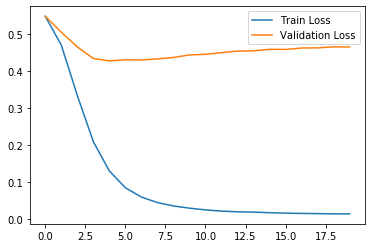

In [422]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [423]:
loss,accuracy = nlp_model.evaluate(X_test_padded_sent, y_test,verbose=1)

2242/2242 [==============================] - 0s 101us/sample - loss: 0.4654 - acc: 0.5901


In [424]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.46542560163117697
Val Accuracy: 59.00981426239014


In [427]:
y_test_validate = test_pol_validation[['polarity']]
loss,accuracy = nlp_model.evaluate(test_validation_padded_sent,y_test_validate,
                                         verbose=1,batch_size=batch_size)

1500/1500 [==============================] - 0s 91us/sample - loss: 0.9687 - acc: 0.4087


In [428]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 0.9686867596308391
Val Accuracy: 40.86666703224182


## Dense Connected Layer - Convolutional1D Layer

In [510]:
padded_sentences.shape

(5235, 29)

In [511]:
X_test_padded_sent.shape

(2244, 29)

In [512]:
y_train.shape

(5235, 1)

In [513]:
vocab_length

7105

In [514]:
length_long_sentence

29

In [730]:

y_train_binary = to_categorical(y_train)
y_train_binary

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]], dtype=float32)

In [731]:
y_test_binary = to_categorical(y_test)
y_test_binary

array([[0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       ...,
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.]], dtype=float32)

In [732]:
# model developing

n_filters, verbose, epochs, batch_size = 70, 1, 16, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
embedding_vec_length = 60

cnn_model = Sequential()

cnn_model.add(Embedding(vocab_length, embedding_vec_length, input_length=length_long_sentence))
cnn_model.add(Conv1D(filters=32, kernel_size=2, padding='same',activation='relu', input_shape=(n_features,embedding_vec_length)))#input_shape=(n_rows,n_features)))
cnn_model.add(Conv1D(filters=64, kernel_size=3, padding='same',activation='relu'))
cnn_model.add(Conv1D(filters=128, kernel_size=4, padding='same',activation='relu'))
#cnn_model.add(Conv1D(filters=n_filters, kernel_size=2, padding='same', activation='relu'))
#cnn_model.add(Dropout(0.5))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Flatten())
#cnn_model.add(Dense(100, activation='tanh'))
cnn_model.add(Dropout(0.2))
cnn_model.add(Dense(3, activation='softmax'))
print(cnn_model.summary())


Model: "sequential_110"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_107 (Embedding)    (None, 29, 60)            434400    
_________________________________________________________________
conv1d_138 (Conv1D)          (None, 29, 32)            3872      
_________________________________________________________________
conv1d_139 (Conv1D)          (None, 29, 64)            6208      
_________________________________________________________________
conv1d_140 (Conv1D)          (None, 29, 128)           32896     
_________________________________________________________________
max_pooling1d_31 (MaxPooling (None, 14, 128)           0         
_________________________________________________________________
flatten_26 (Flatten)         (None, 1792)              0         
_________________________________________________________________
dropout_9 (Dropout)          (None, 1792)           

In [733]:
cnn_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [734]:
# fit network
history = cnn_model.fit(padded_sentences, y_train_binary, epochs=epochs, verbose=verbose, batch_size=batch_size, 
                       validation_data=(X_test_padded_sent, y_test_binary))

Train on 5240 samples, validate on 2246 samples
Epoch 1/16
5240/5240 [==============================] - 15s 3ms/sample - loss: 0.9345 - acc: 0.5567 - val_loss: 0.7722 - val_acc: 0.6723
Epoch 2/16
5240/5240 [==============================] - 3s 646us/sample - loss: 0.6486 - acc: 0.7313 - val_loss: 0.7628 - val_acc: 0.6963
Epoch 3/16
5240/5240 [==============================] - 3s 636us/sample - loss: 0.4478 - acc: 0.8250 - val_loss: 0.8292 - val_acc: 0.7035
Epoch 4/16
5240/5240 [==============================] - 3s 637us/sample - loss: 0.2563 - acc: 0.9109 - val_loss: 0.8808 - val_acc: 0.7075
Epoch 5/16
5240/5240 [==============================] - 3s 641us/sample - loss: 0.1535 - acc: 0.9504 - val_loss: 1.1008 - val_acc: 0.7079
Epoch 6/16
5240/5240 [==============================] - 3s 635us/sample - loss: 0.0939 - acc: 0.9681 - val_loss: 1.4404 - val_acc: 0.7110
Epoch 7/16
5240/5240 [==============================] - 3s 629us/sample - loss: 0.0616 - acc: 0.9803 - val_loss: 1.7827 - val

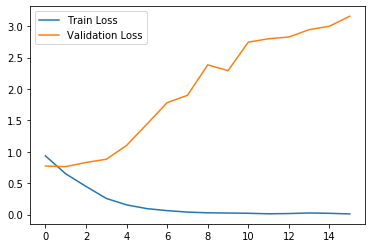

In [735]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [736]:
loss,accuracy = cnn_model.evaluate(X_test_padded_sent, y_test_binary,verbose=1,batch_size=batch_size)

2246/2246 [==============================] - 0s 208us/sample - loss: 3.1596 - acc: 0.6915


In [737]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 3.1595999130901227
Val Accuracy: 69.14514899253845


In [738]:
y_test_validate = test_pol_validation[['polarity']]
y_test_validate_binary = to_categorical(y_test_validate)
loss,accuracy = cnn_model.evaluate(test_validation_padded_sent,y_test_validate_binary,
                                         verbose=1,batch_size=batch_size)

1500/1500 [==============================] - 0s 203us/sample - loss: 11.7167 - acc: 0.3620


In [739]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 11.716730748494466
Val Accuracy: 36.19999885559082


## LSTM

In [740]:
# model developing

n_filters, verbose, epochs, batch_size = 100, 1, 25, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
print('vocab length: {0}'.format(vocab_length))
print('length of long sentence: {0}'.format(length_long_sentence))
lstm_model = Sequential()

lstm_model.add(Embedding(vocab_length, 50, input_length=length_long_sentence))
lstm_model.add(LSTM(128))
lstm_model.add(Dense(100, activation='relu'))
lstm_model.add(Dense(100))
#lstm_model.add(Dropout(0.2))
lstm_model.add(Dense(3, activation='softmax'))
print(lstm_model.summary())


vocab length: 7240
length of long sentence: 29
Model: "sequential_111"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_108 (Embedding)    (None, 29, 50)            362000    
_________________________________________________________________
unified_lstm_72 (UnifiedLSTM (None, 128)               91648     
_________________________________________________________________
dense_216 (Dense)            (None, 100)               12900     
_________________________________________________________________
dense_217 (Dense)            (None, 100)               10100     
_________________________________________________________________
dense_218 (Dense)            (None, 3)                 303       
Total params: 476,951
Trainable params: 476,951
Non-trainable params: 0
_________________________________________________________________
None


- You can now see that we have 361800 new parameters to train. This number comes from vocab_size times the embedding_dim. - Here 7236 * 50

In [741]:
lstm_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [730]:

y_train_binary = to_categorical(y_train)
y_train_binary

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]], dtype=float32)

In [731]:
y_test_binary = to_categorical(y_test)
y_test_binary

array([[0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       ...,
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.]], dtype=float32)

In [743]:
# fit network
history = lstm_model.fit(padded_sentences, y_train_binary, epochs=epochs, batch_size=batch_size, verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test_binary))

Train on 5240 samples, validate on 2246 samples
Epoch 1/25
5240/5240 [==============================] - 27s 5ms/sample - loss: 0.9375 - acc: 0.5571 - val_loss: 0.7962 - val_acc: 0.6518
Epoch 2/25
5240/5240 [==============================] - 13s 2ms/sample - loss: 0.6724 - acc: 0.7162 - val_loss: 0.7569 - val_acc: 0.6808
Epoch 3/25
5240/5240 [==============================] - 12s 2ms/sample - loss: 0.5375 - acc: 0.7802 - val_loss: 0.8239 - val_acc: 0.6728
Epoch 4/25
5240/5240 [==============================] - 12s 2ms/sample - loss: 0.4502 - acc: 0.8242 - val_loss: 0.9155 - val_acc: 0.6670
Epoch 5/25
5240/5240 [==============================] - 12s 2ms/sample - loss: 0.3348 - acc: 0.8836 - val_loss: 0.9375 - val_acc: 0.7057
Epoch 6/25
5240/5240 [==============================] - 12s 2ms/sample - loss: 0.2295 - acc: 0.9240 - val_loss: 1.0733 - val_acc: 0.7150
Epoch 7/25
5240/5240 [==============================] - 12s 2ms/sample - loss: 0.1976 - acc: 0.9359 - val_loss: 0.9561 - val_acc: 

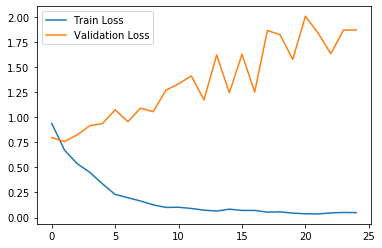

In [744]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [745]:
loss,accuracy = lstm_model.evaluate(X_test_padded_sent, y_test_binary,verbose=1,batch_size=batch_size)

2246/2246 [==============================] - 1s 616us/sample - loss: 1.8690 - acc: 0.6866


In [746]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 1.8690485837516886
Val Accuracy: 68.65538954734802


In [747]:
y_test_validate = test_pol_validation[['polarity']]
y_test_validate_binary = to_categorical(y_test_validate)
loss,accuracy = lstm_model.evaluate(test_validation_padded_sent,y_test_validate_binary,
                                         verbose=1,batch_size=batch_size)

1500/1500 [==============================] - 1s 615us/sample - loss: 4.6620 - acc: 0.3567


In [748]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 4.661969132741293
Val Accuracy: 35.66666543483734


## LSTM and Convolutional 1D

In [751]:
# model developing

n_filters, verbose, epochs, batch_size = 100, 1, 25, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
embedding_vec_length=60
print('X train cols: {0}'.format(n_features))
print('vocab length: {0}'.format(vocab_length))
print('length of long sentence: {0}'.format(length_long_sentence))
lstm_conv_model = Sequential()
lstm_conv_model.add(Embedding(vocab_length, embedding_vec_length, input_length=length_long_sentence))

lstm_conv_model.add(Dense(100, activation='relu'))
lstm_conv_model.add(Dense(100))


lstm_conv_model.add(Conv1D(filters=32, kernel_size=2,padding='same', activation='relu', 
                           input_shape=(n_features,embedding_vec_length)))
lstm_conv_model.add(Conv1D(filters=64, kernel_size=3, padding='same',activation='relu'))
lstm_conv_model.add(Conv1D(filters=128, kernel_size=4, padding='same',activation='relu'))
# lstm_conv_model.add(Conv1D(filters=n_filters, kernel_size=3, activation='relu', input_shape=(n_rows,n_features)))
# lstm_conv_model.add(Conv1D(filters=n_filters, kernel_size=3, activation='relu'))
# #lstm_conv_model.add(Dropout(0.5))
lstm_conv_model.add(MaxPooling1D(pool_size=int(n_features/2)))
lstm_conv_model.add(LSTM(128))

#lstm_conv_model.add(Dropout(0.2))
lstm_conv_model.add(Dense(3, activation='softmax'))
print(lstm_conv_model.summary())


X train cols: 29
vocab length: 7240
length of long sentence: 29
Model: "sequential_114"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_111 (Embedding)    (None, 29, 60)            434400    
_________________________________________________________________
dense_224 (Dense)            (None, 29, 100)           6100      
_________________________________________________________________
dense_225 (Dense)            (None, 29, 100)           10100     
_________________________________________________________________
conv1d_146 (Conv1D)          (None, 29, 32)            6432      
_________________________________________________________________
conv1d_147 (Conv1D)          (None, 29, 64)            6208      
_________________________________________________________________
conv1d_148 (Conv1D)          (None, 29, 128)           32896     
______________________________________________________

In [752]:
lstm_conv_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [753]:

y_train_binary = to_categorical(y_train)
y_train_binary

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]], dtype=float32)

In [754]:
y_test_binary = to_categorical(y_test)
y_test_binary

array([[0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       ...,
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.]], dtype=float32)

In [755]:
# fit network
history = lstm_conv_model.fit(padded_sentences, y_train_binary, epochs=epochs, batch_size=batch_size, verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test_binary))

Train on 5240 samples, validate on 2246 samples
Epoch 1/25
5240/5240 [==============================] - 18s 4ms/sample - loss: 0.9241 - acc: 0.5676 - val_loss: 0.7937 - val_acc: 0.6768
Epoch 2/25
5240/5240 [==============================] - 5s 1ms/sample - loss: 0.7163 - acc: 0.7118 - val_loss: 0.7681 - val_acc: 0.6892
Epoch 3/25
5240/5240 [==============================] - 5s 1ms/sample - loss: 0.5940 - acc: 0.7677 - val_loss: 0.8442 - val_acc: 0.6443
Epoch 4/25
5240/5240 [==============================] - 5s 995us/sample - loss: 0.4793 - acc: 0.8143 - val_loss: 0.8809 - val_acc: 0.6848
Epoch 5/25
5240/5240 [==============================] - 5s 1ms/sample - loss: 0.3614 - acc: 0.8693 - val_loss: 0.8645 - val_acc: 0.6923
Epoch 6/25
5240/5240 [==============================] - 5s 1ms/sample - loss: 0.2803 - acc: 0.9053 - val_loss: 1.0155 - val_acc: 0.6883
Epoch 7/25
5240/5240 [==============================] - 6s 1ms/sample - loss: 0.2159 - acc: 0.9307 - val_loss: 1.1131 - val_acc: 0.68

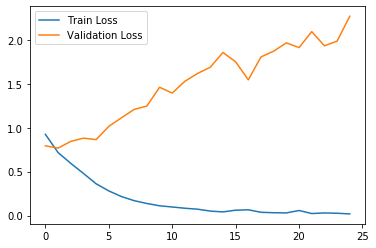

In [756]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [758]:
loss,accuracy = lstm_conv_model.evaluate(X_test_padded_sent, y_test_binary,verbose=1,batch_size=batch_size)

2246/2246 [==============================] - 1s 350us/sample - loss: 2.2688 - acc: 0.6768


In [759]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 2.268753830917372
Val Accuracy: 67.67587065696716


In [760]:
y_test_validate = test_pol_validation[['polarity']]
y_test_validate_binary = to_categorical(y_test_validate)
loss,accuracy = lstm_conv_model.evaluate(test_validation_padded_sent,y_test_validate_binary,
                                         verbose=1,batch_size=batch_size)

1500/1500 [==============================] - 1s 346us/sample - loss: 6.0903 - acc: 0.3500


In [761]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 6.090334706624349
Val Accuracy: 34.99999940395355


## Conv1D and Bidirectional

In [765]:
n_filters, verbose, epochs, batch_size = 100, 1, 25, 32
n_rows, n_features, n_outputs = padded_sentences.shape[0], padded_sentences.shape[1], y_train.shape[0]
embedding_vec_length=60
print('X train cols: {0}'.format(n_features))
print('vocab length: {0}'.format(vocab_length))
print('length of long sentence: {0}'.format(length_long_sentence))
model = Sequential()

model.add(Embedding(vocab_length, embedding_vec_length, input_length=length_long_sentence))
model.add(Dense(128,activation='relu'))
model.add(Conv1D(filters=n_filters, kernel_size=2,padding='same', activation='relu', 
                           input_shape=(n_features,embedding_vec_length)))
model.add(Bidirectional(LSTM(128, return_sequences=True, dropout=0.5)))
model.add(GlobalMaxPool1D())
model.add(Dense(10,activation='relu'))
model.add(Dense(3,activation='softmax'))
print(model.summary())


X train cols: 29
vocab length: 7240
length of long sentence: 29
Model: "sequential_116"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_113 (Embedding)    (None, 29, 60)            434400    
_________________________________________________________________
dense_230 (Dense)            (None, 29, 128)           7808      
_________________________________________________________________
conv1d_150 (Conv1D)          (None, 29, 100)           25700     
_________________________________________________________________
bidirectional_56 (Bidirectio (None, 29, 256)           234496    
_________________________________________________________________
global_max_pooling1d_56 (Glo (None, 256)               0         
_________________________________________________________________
dense_231 (Dense)            (None, 10)                2570      
______________________________________________________

In [766]:
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [767]:
# fit network
history = model.fit(padded_sentences, y_train_binary, epochs=epochs, batch_size=batch_size, verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test_binary))

Train on 5240 samples, validate on 2246 samples
Epoch 1/25
5240/5240 [==============================] - 38s 7ms/sample - loss: 0.9492 - acc: 0.5429 - val_loss: 0.8061 - val_acc: 0.6687
Epoch 2/25
5240/5240 [==============================] - 20s 4ms/sample - loss: 0.6789 - acc: 0.7149 - val_loss: 0.7261 - val_acc: 0.6874
Epoch 3/25
5240/5240 [==============================] - 20s 4ms/sample - loss: 0.5511 - acc: 0.7823 - val_loss: 0.7826 - val_acc: 0.6741
Epoch 4/25
5240/5240 [==============================] - 20s 4ms/sample - loss: 0.4850 - acc: 0.8210 - val_loss: 0.8806 - val_acc: 0.6857
Epoch 5/25
5240/5240 [==============================] - 20s 4ms/sample - loss: 0.4409 - acc: 0.8338 - val_loss: 0.9280 - val_acc: 0.6741
Epoch 6/25
5240/5240 [==============================] - 19s 4ms/sample - loss: 0.3890 - acc: 0.8599 - val_loss: 0.9901 - val_acc: 0.6750
Epoch 7/25
5240/5240 [==============================] - 19s 4ms/sample - loss: 0.3246 - acc: 0.8884 - val_loss: 1.0384 - val_acc: 

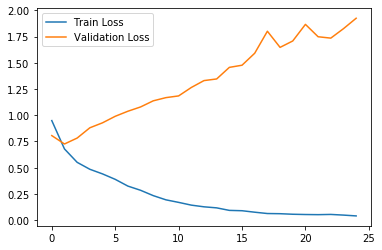

In [768]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [769]:
loss,accuracy = model.evaluate(X_test_padded_sent, y_test_binary,verbose=1,batch_size=batch_size)

2246/2246 [==============================] - 2s 1ms/sample - loss: 1.9251 - acc: 0.6812


In [770]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 1.9250745195845675
Val Accuracy: 68.12110543251038


In [772]:
y_test_validate = test_pol_validation[['polarity']]
y_test_validate_binary = to_categorical(y_test_validate)
loss,accuracy = model.evaluate(test_validation_padded_sent,y_test_validate_binary,
                                         verbose=1,batch_size=batch_size)

1500/1500 [==============================] - 2s 1ms/sample - loss: 5.5445 - acc: 0.3607


In [773]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 5.544484418233235
Val Accuracy: 36.06666624546051


## Hyperparameter Optimization

In [775]:
def create_model(num_filters,kernel_size,vocab_size,embedding_dim,maxlen):
    model = Sequential()
    model.add(Embedding(vocab_size,embedding_dim,input_length=maxlen))
    model.add(Dense(128,activation='relu'))
    model.add(Conv1D(num_filters,kernel_size,activation='relu'))
    model.add(Bidirectional(LSTM(128, return_sequences=True, dropout=0.5)))
    model.add(GlobalMaxPool1D())
    
    model.add(Dense(3,activation='softmax'))
    print(model.summary())
    model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
    return model

In [776]:
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow.keras.callbacks import ModelCheckpoint
# Main settings
epochs = 25
embedding_dim=50
maxlen=length_long_sentence
batch_size=30
verbose=1

vocab_size = max_vocab_index + 5

#parameter grid for grid search
param_grid = dict(num_filters=[32,64,128],
                 kernel_size=[2,3,5],
                 vocab_size = [vocab_size],
                 embedding_dim = [embedding_dim],
                 maxlen = [maxlen])

hyperparam_model = KerasClassifier(build_fn=create_model,
                                  epochs=epochs,
                                  batch_size=batch_size,
                                  verbose=verbose)

grid = RandomizedSearchCV(estimator=hyperparam_model,
                         param_distributions=param_grid,
                         cv=5,
                         verbose=verbose,
                         n_iter=5)

callback_list = [
        EarlyStopping(
            monitor='val_loss',
            patience=10,
            verbose=1,
            mode='auto'
        )
#     ,
#         ModelCheckpoint(
#             monitor='val_acc',
#             save_best_only='True',
#             verbose=1,
#             mode='max'
#         )
    ]

## fit X_train and y_train in grid
grid_result = grid.fit(padded_sentences,y_train_binary)#,callbacks=callback_list)

#Evaluate test set
test_accuracy = grid.score(X_test_padded_sent,y_test_binary)


# Save and evaluate results
print('Results from Grid Search')
print('Best params: {0}'.format(grid_result.best_params_))
print('Best Accuracy: {0}'.format(round(grid_result.best_score_,2)))
print('Test Accuracy: {0}'.format(round(test_accuracy,2)))



Fitting 5 folds for each of 5 candidates, totalling 25 fits


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


Model: "sequential_117"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_114 (Embedding)    (None, 29, 50)            362200    
_________________________________________________________________
dense_233 (Dense)            (None, 29, 128)           6528      
_________________________________________________________________
conv1d_151 (Conv1D)          (None, 25, 32)            20512     
_________________________________________________________________
bidirectional_57 (Bidirectio (None, 25, 256)           164864    
_________________________________________________________________
global_max_pooling1d_57 (Glo (None, 256)               0         
_________________________________________________________________
dense_234 (Dense)            (None, 3)                 771       
Total params: 554,875
Trainable params: 554,875
Non-trainable params: 0
______________________________________________

Epoch 1/25
4192/4192 [==============================] - 23s 5ms/sample - loss: 0.9545 - acc: 0.5446
Epoch 2/25
4192/4192 [==============================] - 14s 3ms/sample - loss: 0.6799 - acc: 0.7130
Epoch 3/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.5392 - acc: 0.7944
Epoch 4/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.4699 - acc: 0.8208
Epoch 5/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.3935 - acc: 0.8578
Epoch 6/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.2922 - acc: 0.9055
Epoch 7/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.2254 - acc: 0.9253
Epoch 8/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.1608 - acc: 0.9523
Epoch 9/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.1303 - acc: 0.9630
Epoch 10/25
4192/4192 [==============================] - 13s 3ms/sample - loss: 0.0979 - acc: 0.9721

4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0416 - acc: 0.9893
Epoch 14/25
4192/4192 [==============================] - 15s 3ms/sample - loss: 0.0426 - acc: 0.9893
Epoch 15/25
4192/4192 [==============================] - 15s 3ms/sample - loss: 0.0387 - acc: 0.9890
Epoch 16/25
4192/4192 [==============================] - 15s 3ms/sample - loss: 0.0299 - acc: 0.9924
Epoch 17/25
4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0284 - acc: 0.9917
Epoch 18/25
4192/4192 [==============================] - 15s 3ms/sample - loss: 0.0311 - acc: 0.9912
Epoch 19/25
4192/4192 [==============================] - 15s 3ms/sample - loss: 0.0272 - acc: 0.9912
Epoch 20/25
4192/4192 [==============================] - 15s 3ms/sample - loss: 0.0241 - acc: 0.9926
Epoch 21/25
4192/4192 [==============================] - 14s 3ms/sample - loss: 0.0157 - acc: 0.9950
Epoch 22/25
4192/4192 [==============================] - 14s 3ms/sample - loss: 0.0123 - acc: 0.9964
Ep

...

4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0543 - acc: 0.9850
Epoch 14/25
4192/4192 [==============================] - 17s 4ms/sample - loss: 0.0466 - acc: 0.9890
Epoch 15/25
4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0466 - acc: 0.9866
Epoch 16/25
4192/4192 [==============================] - 16s 4ms/sample - loss: 0.0516 - acc: 0.9850
Epoch 17/25
4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0381 - acc: 0.9895
Epoch 18/25
4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0333 - acc: 0.9905
Epoch 19/25
4192/4192 [==============================] - 16s 4ms/sample - loss: 0.0347 - acc: 0.9890
Epoch 20/25
4192/4192 [==============================] - 17s 4ms/sample - loss: 0.0280 - acc: 0.9933
Epoch 21/25
4192/4192 [==============================] - 16s 4ms/sample - loss: 0.0205 - acc: 0.9940
Epoch 22/25
4192/4192 [==============================] - 15s 4ms/sample - loss: 0.0178 - acc: 0.9943
Ep

1048/1048 [==============================] - 11s 11ms/sample - loss: 2.3821 - acc: 0.6813
Model: "sequential_139"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_136 (Embedding)    (None, 29, 50)            362200    
_________________________________________________________________
dense_277 (Dense)            (None, 29, 128)           6528      
_________________________________________________________________
conv1d_173 (Conv1D)          (None, 28, 128)           32896     
_________________________________________________________________
bidirectional_79 (Bidirectio (None, 28, 256)           263168    
_________________________________________________________________
global_max_pooling1d_79 (Glo (None, 256)               0         
_________________________________________________________________
dense_278 (Dense)            (None, 3)                 771       
Total params: 665,563
Traina

Epoch 1/25
4192/4192 [==============================] - 31s 7ms/sample - loss: 0.9500 - acc: 0.5479
Epoch 2/25
4192/4192 [==============================] - 22s 5ms/sample - loss: 0.6646 - acc: 0.7211
Epoch 3/25
4192/4192 [==============================] - 24s 6ms/sample - loss: 0.5237 - acc: 0.7925
Epoch 4/25
4192/4192 [==============================] - 22s 5ms/sample - loss: 0.4269 - acc: 0.8442
Epoch 5/25
4192/4192 [==============================] - 22s 5ms/sample - loss: 0.3073 - acc: 0.8934
Epoch 6/25
4192/4192 [==============================] - 21s 5ms/sample - loss: 0.2277 - acc: 0.9234
Epoch 7/25
4192/4192 [==============================] - 19s 5ms/sample - loss: 0.1810 - acc: 0.9399
Epoch 8/25
4192/4192 [==============================] - 19s 5ms/sample - loss: 0.1608 - acc: 0.9485
Epoch 9/25
4192/4192 [==============================] - 21s 5ms/sample - loss: 0.1096 - acc: 0.9673
Epoch 10/25
4192/4192 [==============================] - 20s 5ms/sample - loss: 0.0970 - acc: 0.9709

[Parallel(n_jobs=1)]: Done  25 out of  25 | elapsed: 187.4min finished


Model: "sequential_142"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_139 (Embedding)    (None, 29, 50)            362200    
_________________________________________________________________
dense_283 (Dense)            (None, 29, 128)           6528      
_________________________________________________________________
conv1d_176 (Conv1D)          (None, 28, 128)           32896     
_________________________________________________________________
bidirectional_82 (Bidirectio (None, 28, 256)           263168    
_________________________________________________________________
global_max_pooling1d_82 (Glo (None, 256)               0         
_________________________________________________________________
dense_284 (Dense)            (None, 3)                 771       
Total params: 665,563
Trainable params: 665,563
Non-trainable params: 0
______________________________________________

## Fit the model using best params

In [777]:
vocab_size = grid_result.best_params_['vocab_size']
num_filters = grid_result.best_params_['num_filters']
kernel_size = grid_result.best_params_['kernel_size']
embedding_dim = grid_result.best_params_['embedding_dim']
maxlen = grid_result.best_params_['maxlen']

# Build fine model with best param
fine_model = create_model(num_filters,kernel_size,vocab_size,embedding_dim,maxlen)



Model: "sequential_143"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_140 (Embedding)    (None, 29, 50)            362200    
_________________________________________________________________
dense_285 (Dense)            (None, 29, 128)           6528      
_________________________________________________________________
conv1d_177 (Conv1D)          (None, 28, 128)           32896     
_________________________________________________________________
bidirectional_83 (Bidirectio (None, 28, 256)           263168    
_________________________________________________________________
global_max_pooling1d_83 (Glo (None, 256)               0         
_________________________________________________________________
dense_286 (Dense)            (None, 3)                 771       
Total params: 665,563
Trainable params: 665,563
Non-trainable params: 0
______________________________________________

In [778]:
# fit network
history = fine_model.fit(padded_sentences, y_train_binary, epochs=15,
                                  batch_size=batch_size,
                                  verbose=verbose,
                       validation_data=(X_test_padded_sent, y_test_binary))

Train on 5240 samples, validate on 2246 samples
Epoch 1/15
5240/5240 [==============================] - 53s 10ms/sample - loss: 0.9024 - acc: 0.5773 - val_loss: 0.7531 - val_acc: 0.6799
Epoch 2/15
5240/5240 [==============================] - 30s 6ms/sample - loss: 0.6389 - acc: 0.7355 - val_loss: 0.7284 - val_acc: 0.7048
Epoch 3/15
5240/5240 [==============================] - 29s 6ms/sample - loss: 0.5190 - acc: 0.8034 - val_loss: 0.7948 - val_acc: 0.6892
Epoch 4/15
5240/5240 [==============================] - 29s 6ms/sample - loss: 0.4088 - acc: 0.8546 - val_loss: 0.7942 - val_acc: 0.7164
Epoch 5/15
5240/5240 [==============================] - 29s 6ms/sample - loss: 0.3096 - acc: 0.8966 - val_loss: 0.8605 - val_acc: 0.7289
Epoch 6/15
5240/5240 [==============================] - 29s 6ms/sample - loss: 0.2314 - acc: 0.9252 - val_loss: 0.9217 - val_acc: 0.7177
Epoch 7/15
5240/5240 [==============================] - 29s 6ms/sample - loss: 0.1768 - acc: 0.9435 - val_loss: 1.0935 - val_acc:

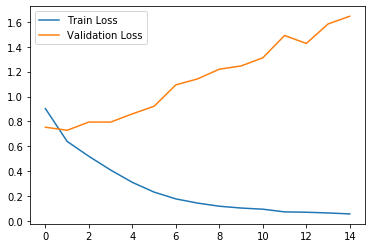

In [779]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(train_loss,label='Train Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend();

In [781]:
loss,accuracy = fine_model.evaluate(X_test_padded_sent, y_test_binary,verbose=1,batch_size=batch_size)

2246/2246 [==============================] - 5s 2ms/sample - loss: 1.6452 - acc: 0.6852


In [782]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 1.6452304334218015
Val Accuracy: 68.52181553840637


In [783]:
y_test_validate = test_pol_validation[['polarity']]
y_test_validate_binary = to_categorical(y_test_validate)
loss,accuracy = fine_model.evaluate(test_validation_padded_sent,y_test_validate_binary,
                                         verbose=1,batch_size=batch_size)

1500/1500 [==============================] - 3s 2ms/sample - loss: 4.6382 - acc: 0.3527


In [784]:
print("Val Loss: {0}".format(loss))
print("Val Accuracy: {0}".format(accuracy*100))

Val Loss: 4.638177103996277
Val Accuracy: 35.26666760444641
